<a href="https://colab.research.google.com/github/AndresSebas15/Mobility_economy/blob/main/Mobility_economy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introduction

OBJECTIVE: **Evaluate how urban mobility relates to economic productivity in the main Latin American cities**.
DATASET:

TomTom Traffic Index and OECD Cities, which must be cleaned, then combined and analyzed to identify which cities are worth investing in transportation infrastructure.

##  Step 1: Load and explore

### 1.1 Data loading and quick overview

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt

In [ ]:
# load files
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
# show the first 5 rows of traffic
traffic.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# show the first 5 rows of eco
eco.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** If you don't use `print()`, the table will look better.


---

## Step 2: Explore, clean, and prepare the data

### 2.1 Explore the structure and data types

**Objective:**
Identify columns with incorrect types, distributions, and nulls, and note the columns that require conversion.


In [ ]:
# Examine the structure of traffic
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

In the structure of the traffic DF, we observe that:
- The columns `UpdateTimeUTC` and `UpdateTimeUTC` are of type object; they need to be converted to Date type.
- There are no null values in any column.

In [ ]:
# Examine the structure of eco
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


In the structure of the eco DF, we observe that:
- The columns `City GDP/capita`, `Unemployment %`, `PM2.5 (μg/m³)` and `Population (M)` are of type object; they need to be converted to integer (int).
- There are no null values in any column.

### 2.2 Rename columns


In [ ]:
# Standardize the column names of traffic

traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_hist_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})

# verify changes
traffic.columns


Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

In [ ]:
# Standardize the column names of eco
# your code here
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25',
    'Population (M)':'population'
})
# verify changes
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population'],
      dtype='object')


### 2.3 Fix numeric and date formats

**🎯Objective:**
Ensure that date and numeric columns are in the correct formats to allow accurate analysis, calculations, and comparisons.

**STEPS:**

- The date columns in `traffic` are converted to `datetime` format. Make the conversion error-proof.
- In the `eco` dataset, clean the numeric values:
    - In `city_gdp_capita`: remove thousands separators (`.`) and replace commas (`','`) with periods (`'.'`) before converting to `float`.
    - In `unemployment_pct`: remove the percentage symbol (`%`) and replace commas (`','`) with periods (`'.'`) before converting to `float`.
    - In `population_m`: replace commas (`','`) with periods (`'.'`) before converting to `float`.
- Finally, a new column called `population` is created by multiplying `population_m` by 1,000,000 to obtain the total population.


In [ ]:
# Convert the traffic columns to date type with pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'])
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'])

# verify the change
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   traffic_index_week_ago           1004464 non-null  float64       
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

In [ ]:

# Clean separators and convert numeric columns in eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '').str.replace(',', '.').astype(float)
eco['population'] = eco['population'].astype(str).str.replace(',', '.').astype(float)

# Calculate total population in absolute units (multiply * 1000000)
eco['population'] = eco['population']*1000000

# verify the change
eco.info()
eco.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population        30 non-null     float64
dtypes: float64(3), int64(1), object(3)
memory usage: 1.8+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13600000.0



---

## Step 3: Extract year and filter

Extracting the year makes it possible to filter the information and work only with the most recent and relevant period.

### 3.1 Extract year column and filter 2024

**STEPS:**

- Since the `traffic` DataFrame has no year column, the `.dt.year` attribute is used on its date column to create a new column called `year`.
- Rows where the year is **2024** are filtered.
- `.copy()` is used to create two new DataFrames (`traffic_2024` and `eco_2024`) to avoid modifying the original dataset.

In [ ]:
# Extract the year from the dates in update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verify change
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filter the records from 2024
traffic_2024 = traffic[traffic['year']== 2024].copy()
eco_2024 = eco[eco['year']== 2024].copy()

# Review new dataframes
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3900000.0



---

## Step 4: Analyze and summarize mobility data

The traffic dataset contains **multiple records per city**. In this section, annual averages per city are calculated to simplify the analysis and get a clearer view of the general trends.

### 4.1 Calculate traffic averages by city


**STEPS:**

- The data is grouped by `city`, `country` and `year`.
- The average is calculated **only for the most relevant traffic metrics**: such as `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, and travel times (`travel_time_live_per_10kms_mins` and `travel_time_hist_per_10kms_mins`).
- The result is saved as `traffic_city_year_2024`, keeping the columns as variables (not indexes).


In [ ]:
# Calculate traffic averages by city, country, and year
traffic_city_year_2024 = traffic_2024.groupby(['city', 'country', 'year']).agg({
    'jams_delay': 'mean',
    'traffic_index_live': 'mean',
    'jams_length_kms': 'mean',
    'jams_count': 'mean',
    'mins_delay': 'mean',
    'travel_time_live_per_10kms_mins': 'mean',
    'travel_time_hist_per_10kms_mins': 'mean'
}).reset_index()

# Show result
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


The city with the highest average traffic time is Mexico City, followed by New York and Tokyo.


---

## Step 5: Merge mobility and economy

Combining datasets lets you analyze how economic indicators relate to mobility indicators.

### 5.1 Merge traffic (main table) with economic indicators

**Objective:**
Combine the traffic and economic information into a single DataFrame to analyze how economic conditions relate to urban mobility.


In [ ]:
# Select key traffic and economy columns
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Use .copy() to create the two new reduced datasets
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Merge datasets
merged = pd.merge(traffic_2024_small,eco_2024_small, on =["city", "year"], how = "inner" )

# Show the first 5 rows
merged.head(5)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0



---

## Step 6: Visualization and relationship analysis

### 6.1 Visualize relationships between economy and traffic


**STEPS:**
- The `seaborn` and `matplotlib.pyplot` libraries are used to generate the charts.
- The distribution of **traffic** (`jams_delay`) is visualized using:
    - **Boxplot** → to observe the mean and median and detect outliers.
- The distribution of the **economy** (`city_gdp_capita`) is visualized using:
    - **Histogram** → to analyze the shape of the distribution and the average GDP per capita.
- Finally, **both variables are compared** to see whether there is any relationship between them, using a single bar chart that shows both indicators.

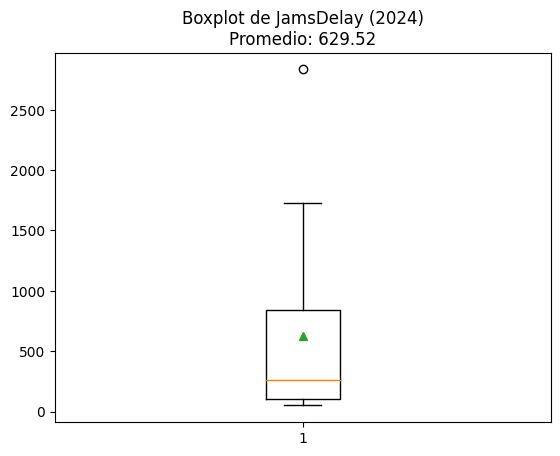

In [ ]:
# Create a boxplot to observe the behavior of congestion minutes (JamsDelay)
plt.boxplot(merged["jams_delay"],showmeans=True )

# get the mean to display it in the title
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


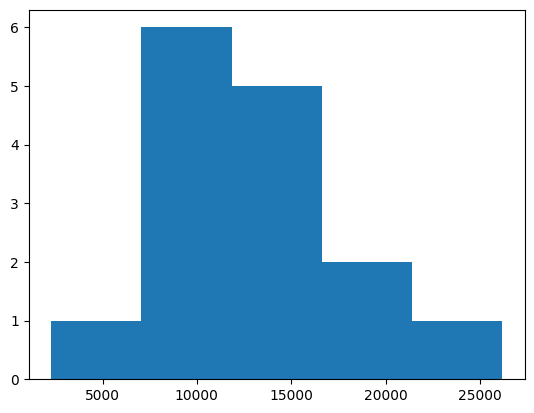

In [ ]:
# Create a histogram to see the distribution of the economy (city_gdp_capita)
plt.hist(merged["city_gdp_capita"], bins=5)
plt.show()


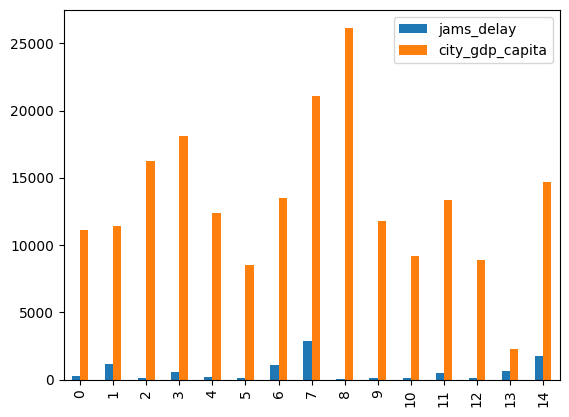

In [ ]:
# Bar chart to compare jams_delay and city_gdp_capita by city
merged.plot(kind='bar', y=['jams_delay', 'city_gdp_capita'])
plt.xticks(rotation=90)
plt.show()

INSIGHT:
* It cannot necessarily be concluded that cities with higher GDP per capita also have more congestion. To determine the relationship between these two variables, a correlation analysis is needed; however, no direct relationship is apparent. For example, record 8 has the highest GDP but very little traffic time, while record 7, the second highest in GDP, has much more time in traffic.


---

## Step 7: Export and document results

### 7.1 Save final dataset


In [ ]:
# Export the final dataset as CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

## EXECUTIVE SUMMARY

**Context & objective:**  
For 2024, across the Latin American countries ('BRA', 'COL', 'ARG', 'PER', 'MEX', 'URY', 'CHL') and 15 cities ('belo-horizonte', 'bogota', 'brasilia', 'buenos-aires', 'curitiba', 'fortaleza', 'lima', 'mexico-city', 'montevideo', 'porto-alegre', 'recife', 'rio-de-janeiro', 'salvador', 'santiago', 'sao-paulo'), no clear relationship was found between economic performance and urban mobility.

**Data coverage:**  
For this conclusion, the reference variables were "year", "city", "country", "city_gdp_capita" and "jams_delay", which best represent this relationship. Variables such as 'update_time_utc', 'update_time_utc_week_ago', 'unemployment_pct' and 'population' were also considered; these went through a cleaning process, reviewing their format and making the necessary adjustments documented in the code. To preserve the relationship across all these variables, an inner join was used, ensuring that all values were available for the analysis.

**Methodology (high level) and findings:**  
For visual validation, a box plot was created for the traffic time values, identifying one outlier, with a mean of 629.52. A histogram of GDP per capita values shows that the distribution is not entirely normal, with values concentrated between 10,000 and 15,000.
In addition, a bar chart is used to visually identify the relationship between GDP per capita and traffic time.

**Recommendations**  
For a complete analysis, variables such as climate, cars per household, access to public transportation services, geographic complexity, etc. should be considered. However, based on the data analyzed, the city with the highest average traffic time is Mexico City, followed by New York and Tokyo, where infrastructure investment actions could be taken to reduce traffic.


In [ ]:
merged['country'].unique()
merged['city'].unique()

array(['belo-horizonte', 'bogota', 'brasilia', 'buenos-aires', 'curitiba',
       'fortaleza', 'lima', 'mexico-city', 'montevideo', 'porto-alegre',
       'recife', 'rio-de-janeiro', 'salvador', 'santiago', 'sao-paulo'],
      dtype=object)